In [215]:
import numpy as np
import scipy
import pandas as pd
import cv2
from matplotlib import pyplot as plt
from PIL import Image
from PIL.ExifTags import TAGS
import pillow_heif
import glob

In [216]:

# Adjust according to your checkerboard
CHECKERBOARD = (7, 7)   # (corners per row, corners per column)
SQUARE_SIZE = 35.0      # size of a square in mm (change to your square size)

flags = cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE

# Paths to your 13 images (PNG, JPG, HEIC converted)
images = glob.glob("checkerboard/*.png")  # change folder / extension

# === Prepare object points (0,0,0), (1,0,0), (2,0,0) ... in real units ===
objp = np.zeros((CHECKERBOARD[0]*CHECKERBOARD[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:CHECKERBOARD[0], 0:CHECKERBOARD[1]].T.reshape(-1, 2)
objp *= SQUARE_SIZE

# Arrays to store points
objpoints = []  # 3D points in real world
imgpoints = []  # 2D points in image plane

# === Process all images ===
for fname in images:
    img = cv2.imread(fname)
    scale = 0.2
    img = cv2.resize(img, (0,0), fx=scale, fy=scale)  # resize for faster processing
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Find checkerboard corners
    ret, corners = cv2.findChessboardCornersSB(gray, CHECKERBOARD, flags)

    if ret:
        objpoints.append(objp)

        # refine corner location
        corners2 = cv2.cornerSubPix(gray, corners, (11,11), (-1,-1),
                                    criteria=(cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
                                              30, 0.001))
        imgpoints.append(corners2)

        # draw and show for sanity check
        cv2.drawChessboardCorners(img, CHECKERBOARD, corners2, ret)
        cv2.imshow('img', gray)
        cv2.waitKey(2000)
    else:
        cv2.imshow('img', gray)
        cv2.waitKey(2000)
        print(f"Checkerboard not detected in {fname}")

cv2.destroyAllWindows()

# === Calibrate ===
ret, K, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, gray.shape[::-1], None, None)

print("Calibration RMS error:", ret)
print("Intrinsic matrix K:\n", K)
print("Distortion coefficients:\n", dist.ravel())

Checkerboard not detected in checkerboard\IMG_0227.png
Checkerboard not detected in checkerboard\IMG_0228.png
Checkerboard not detected in checkerboard\IMG_0230.png
Checkerboard not detected in checkerboard\IMG_0231.png
Checkerboard not detected in checkerboard\IMG_0232.png
Checkerboard not detected in checkerboard\IMG_0235.png
Calibration RMS error: 0.4941181440328086
Intrinsic matrix K:
 [[670.0615007    0.         279.41488024]
 [  0.         656.6027988  350.69447592]
 [  0.           0.           1.        ]]
Distortion coefficients:
 [ 0.11194656 -0.38836361 -0.01059962 -0.01471068  0.24447907]


In [217]:
# Load two poses of an image
img1 = cv2.imread("./pose1.png")
img2 = cv2.imread("./pose2.png")

# Resize images to fit on screen
scale = 0.2
img1 = cv2.resize(img1, (int(img1.shape[1] * scale), int(img1.shape[0] * scale)))
img2 = cv2.resize(img2, (int(img2.shape[1] * scale), int(img2.shape[0] * scale)))

combined = np.hstack((img1, img2))

cv2.imshow("Two-view", combined)
cv2.waitKey(1000)
cv2.destroyAllWindows()

In [218]:
# Convert the loaded image to grayscale
gray_img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray_img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

combined_gray = np.hstack((gray_img1, gray_img2))

cv2.imshow("Two-view Gray", combined_gray)
cv2.waitKey(1000)
cv2.destroyAllWindows()

# Extrinsic Calibration

## Salient Point Matching

### Salient Points Detection

In [219]:
# SIFT
sift = cv2.SIFT_create()

kp1 = sift.detect(gray_img1,None)
kp2 = sift.detect(gray_img2,None)
 
sift_img1=cv2.drawKeypoints(gray_img1,kp1,img1)
sift_img2=cv2.drawKeypoints(gray_img2,kp2,img2)

combined_sift = np.hstack((sift_img1, sift_img2))

cv2.imshow("SIFT points", combined_sift)
cv2.waitKey(1000)
cv2.destroyAllWindows()

In [220]:
# ORB
orb = cv2.ORB_create()

kp1 = orb.detect(gray_img1,None)
kp2 = orb.detect(gray_img2,None)

orb_img1 = cv2.drawKeypoints(gray_img1,kp1,img1)
orb_img2 = cv2.drawKeypoints(gray_img2,kp2,img2)

combined_orb = np.hstack((orb_img1, orb_img2))

cv2.imshow("ORB points", combined_orb)
cv2.waitKey(1000)
cv2.destroyAllWindows()

In [221]:
# SURF
# Note: SURF is patented and may not be available in all OpenCV installations

#surf = cv2.xfeatures2d.SURF_create()

#kp1 = surf.detect(gray_img1,None)
#kp2 = surf.detect(gray_img2,None)

#surf_img1 = cv2.drawKeypoints(gray_img1,kp1,img1)
#surf_img2 = cv2.drawKeypoints(gray_img2,kp2,img2)

#combined_surf = np.hstack((surf_img1, surf_img2))

#cv2.imshow("SURF points", combined_surf)
#cv2.waitKey(1000)
#cv2.destroyAllWindows()


In [222]:
# AKAZE
akaze = cv2.AKAZE_create()

kp1 = akaze.detect(gray_img1,None)
kp2 = akaze.detect(gray_img2,None)

akaze_img1 = cv2.drawKeypoints(gray_img1,kp1,img1)
akaze_img2 = cv2.drawKeypoints(gray_img2,kp2,img2)

combined_akaze = np.hstack((akaze_img1, akaze_img2))

cv2.imshow("AKAZE points", combined_akaze)
cv2.waitKey(1000)
cv2.destroyAllWindows()

In [223]:
# Define the model to use for keypoint description
model = cv2.SIFT_create()

kp1, des1 = model.detectAndCompute(gray_img1, None)
kp2, des2 = model.detectAndCompute(gray_img2, None)

### Salient Points Matching

In [224]:
# BRUTE-FORCE
bf = cv2.BFMatcher()

bf_matches = bf.knnMatch(des1, des2, k=2)

# Lowe's ratio test
good_matches = []
for m,n in bf_matches:
    if m.distance < 0.8 * n.distance:
        good_matches.append(m)
        
bf_matched_img = cv2.drawMatches(img1, kp1, img2, kp2, good_matches, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

cv2.imshow("Brute Force Matched Points", bf_matched_img)
cv2.waitKey(1000)
cv2.destroyAllWindows()

In [225]:
# FLANN

flann_params = dict(algorithm=1, trees=5)
search_params = dict(checks=50)

flann = cv2.FlannBasedMatcher(flann_params, search_params)

#flann_matches = flann.knnMatch(des1, des2, k=2)

matches_1to2 = flann.knnMatch(des1, des2, k=2) 
matches_2to1 = flann.knnMatch(des2, des1, k=2)

# Lowe's ratio test
good_matches_1to2 = []
for m,n in matches_1to2:
    if m.distance < 0.9 * n.distance:
        good_matches_1to2.append(m)
        
good_matches_2to1 = []
for m,n in matches_2to1:
    if m.distance < 0.9 * n.distance:
        good_matches_2to1.append(m)
        
# Symmetric test
sym_matches = []
for m1 in good_matches_1to2:
    for m2 in good_matches_2to1:
        if m1.queryIdx == m2.trainIdx and m2.queryIdx == m1.trainIdx:
            sym_matches.append(m1)
            break
        
flann_matches_knn = [[m] for m in sym_matches] 
        
flann_matched_img = cv2.drawMatchesKnn(img1, kp1, img2, kp2, flann_matches_knn, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

cv2.imshow("FLANN Matched Points", flann_matched_img)
cv2.waitKey(1000)
cv2.destroyAllWindows()


## Relative Pose Estimation

Inliers after RANSAC: 103
Rotation:
 [[ 0.89565584  0.34801293  0.27692528]
 [ 0.40587897 -0.89416445 -0.18902962]
 [ 0.18183199  0.28170363 -0.94211475]]
Translation:
 [[-0.87398808]
 [ 0.23078926]
 [-0.42764606]]


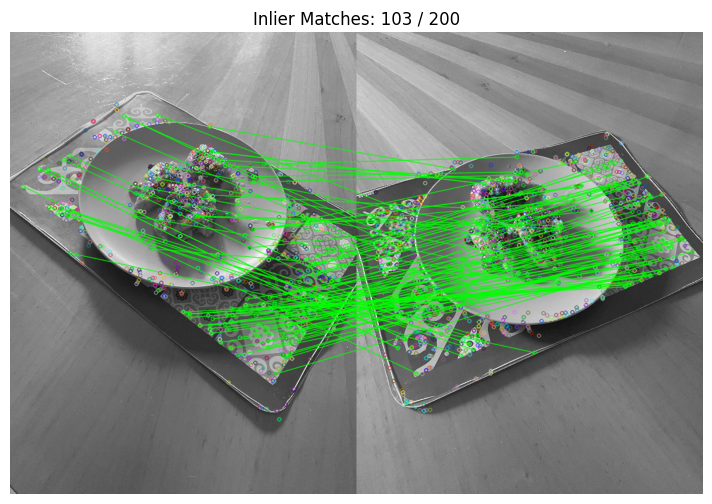

In [226]:
# Standard RANSAC

pts1 = np.float32([kp1[m.queryIdx].pt for m in sym_matches])
pts2 = np.float32([kp2[m.trainIdx].pt for m in sym_matches])

F, mask = cv2.findFundamentalMat(pts1, pts2, cv2.RANSAC, 3.0)

E = K.T @ F @ K

inliers1 = pts1[mask.ravel() == 1]
inliers2 = pts2[mask.ravel() == 1]

print("Inliers after RANSAC:", len(inliers1))

_, R, t, mask_pose = cv2.recoverPose(E, inliers1, inliers2)

print("Rotation:\n", R)
print("Translation:\n", t)

inlier_matches = [sym_matches[i] for i, m in enumerate(mask.ravel()) if m == 1]
img_matches = cv2.drawMatches(img1, kp1, img2, kp2, inlier_matches, None,
                              matchColor=(0, 255, 0), singlePointColor=(255, 0, 0),
                              matchesMask=None, flags=2)


plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
plt.title(f"Inlier Matches: {len(inliers1)} / {len(pts1)}")
plt.axis("off")
plt.show()

## Scale Estimation

In [227]:
points1 = []
points2 = []

def click_event(event, x, y, flags, param):
    global points1, points2, img_display, current_image
    if event == cv2.EVENT_LBUTTONDOWN:
        # Append to the appropriate list
        if current_image == 1:
            points1.append((x, y))
        elif current_image == 2:
            points2.append((x, y))
        
        # Draw circle on the display image
        cv2.circle(img_display, (x, y), 5, (0, 0, 255), -1)
        cv2.imshow("Select 4 corners", img_display)

        # Close window after selecting 4 points
        if (current_image == 1 and len(points1) == 4) or (current_image == 2 and len(points2) == 4):
            cv2.destroyAllWindows()

# Function to select points on an image
def select_points(img, image_number):
    global img_display, current_image
    current_image = image_number
    img_display = img.copy()
    cv2.imshow("Select 4 corners", img_display)
    cv2.setMouseCallback("Select 4 corners", click_event)
    cv2.waitKey(0)

# Select points for img1
select_points(img1, 1)

# Select points for img2
select_points(img2, 2)

print("Points in img1:", points1)
print("Points in img2:", points2)

points1 = np.array(points1, dtype=np.float32)
points2 = np.array(points2, dtype=np.float32)

Points in img1: [(357, 535), (421, 453), (518, 522), (459, 613)]
Points in img2: [(522, 424), (467, 348), (541, 321), (597, 391)]


In [228]:
def compute_scale_from_card(pts1, pts2, K, R, t_unit, obj_card_pts):
    """
    pts1, pts2: 4x2 arrays of card corner positions in rectified left/right images
    K: intrinsics
    R, t_unit: rotation and unit translation from recoverPose
    obj_card_pts: known 3D coords of card corners (e.g., mm)
    """
    P1 = K @ np.hstack((np.eye(3), np.zeros((3,1))))
    P2 = K @ np.hstack((R, t_unit.reshape(3,1)))

    # triangulate card corners
    pts1_h = pts1.T.astype(np.float32)
    pts2_h = pts2.T.astype(np.float32)
    X_h = cv2.triangulatePoints(P1, P2, pts1_h, pts2_h)
    X = (X_h[:3] / X_h[3]).T  # Nx3

    # compute reconstructed width
    rec_width = np.linalg.norm(X[0] - X[1])
    true_width = np.linalg.norm(obj_card_pts[0] - obj_card_pts[1])

    scale = true_width / rec_width
    return scale

In [229]:
width_mm = 68.00
height_mm = 72.00

obj_card_pts = np.array([
    [0, 0],
    [width_mm, 0],
    [width_mm, height_mm],
    [0, height_mm]
], dtype=np.float32)

scale = compute_scale_from_card(points1, points2, K, R, t, obj_card_pts)
t_metric = t * scale

print("Original translation vector:\n", t.ravel())
print("Scaled translation vector (mm):\n", t_metric.ravel())


Original translation vector:
 [-0.87398808  0.23078926 -0.42764606]
Scaled translation vector (mm):
 [-353.62454348   93.37970344 -173.02998509]


# Dense Reconstruction

## Rectification

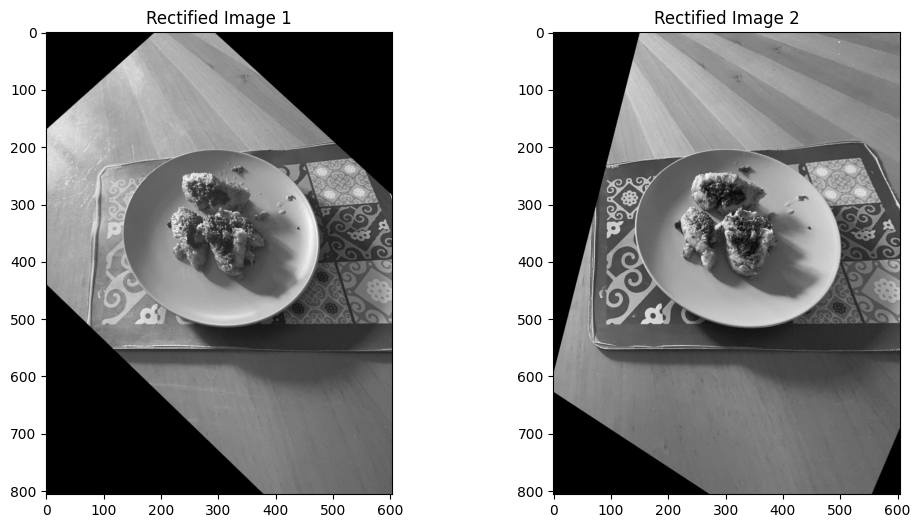

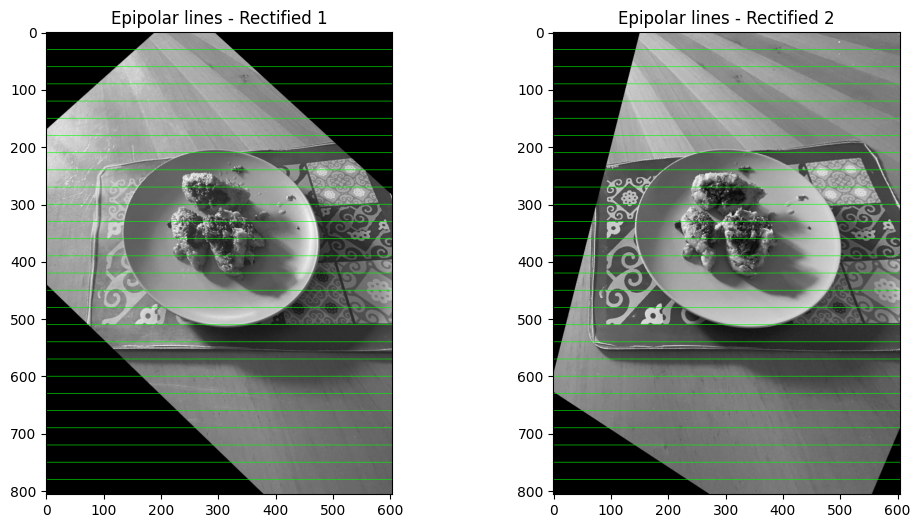

In [231]:
F, mask_F = cv2.findFundamentalMat(inliers1, inliers2, method=cv2.RANSAC, ransacReprojThreshold=1.0, confidence=0.999)

h, w = img1.shape[:2]
retval, H1, H2 = cv2.stereoRectifyUncalibrated(
    np.float32(inliers1), np.float32(inliers2), F, imgSize=(w, h)
)

if not retval:
    raise RuntimeError("Rectification failed")

img1_rect = cv2.warpPerspective(gray_img1, H1, (w, h))
img2_rect = cv2.warpPerspective(gray_img2, H2, (w, h))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img1_rect, cmap='gray')
plt.title("Rectified Image 1")
plt.subplot(1, 2, 2)
plt.imshow(img2_rect, cmap='gray')
plt.title("Rectified Image 2")
plt.show()

def draw_epipolar_lines(img, step=30):
    img_color = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    for y in range(0, img.shape[0], step):
        cv2.line(img_color, (0, y), (img.shape[1], y), (0, 255, 0), 1)
    return img_color

img1_lines = draw_epipolar_lines(img1_rect)
img2_lines = draw_epipolar_lines(img2_rect)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img1_lines[..., ::-1])
plt.title("Epipolar lines - Rectified 1")
plt.subplot(1, 2, 2)
plt.imshow(img2_lines[..., ::-1])
plt.title("Epipolar lines - Rectified 2")
plt.show()

In [235]:

# Get image size
img_size = img1.shape[:2][::-1]
print("Image size:", img_size)

# Compute the rectification transforms
# alpha=-1 ensures all pixels are retained and image is zoomed
R1, R2, P1, P2, Q, _, _ = cv2.stereoRectify(
    K, dist,
    K, dist,
    img_size, R, t_metric,
    alpha=0
)

print("R1:\n", R1)
print("R2:\n", R2)
print("P1:\n", P1)
print("P2:\n", P2)

# Compute the undistortion and rectification maps
map1_x, map1_y = cv2.initUndistortRectifyMap(K, dist, R2, P2, img_size, cv2.CV_32FC1)
map2_x, map2_y = cv2.initUndistortRectifyMap(K, dist, R1, P1, img_size, cv2.CV_32FC1)

print("Map1_x shape:", map1_x.shape)
print("Map1_y shape:", map1_y.shape)

# Remap the images to apply the rectification
rectified_left = cv2.remap(img1, map1_x, map1_y, cv2.INTER_LINEAR)
rectified_right = cv2.remap(img2, map2_x, map2_y, cv2.INTER_LINEAR)


cv2.imwrite('rectified_left_image.jpg', rectified_left)
cv2.imwrite('rectified_right_image.jpg', rectified_right)
cv2.imshow('Rectified Left', rectified_left)
cv2.imshow('Rectified Right', rectified_right)
cv2.waitKey(1000)
cv2.destroyAllWindows()

Image size: (604, 806)
R1:
 [[ 0.76687976  0.63099215 -0.11723627]
 [-0.14051126 -0.01316604 -0.98999154]
 [-0.62622043  0.77567748  0.07856473]]
R2:
 [[ 0.87398808 -0.23078926  0.42764606]
 [-0.40458537  0.14187976  0.90342726]
 [-0.26917563 -0.96260399  0.03062726]]
P1:
 [[ 1.09215547e+03  0.00000000e+00 -9.23309619e+02  0.00000000e+00]
 [ 0.00000000e+00  1.09215547e+03 -4.26776314e+02  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00  0.00000000e+00]]
P2:
 [[ 1.09215547e+03  0.00000000e+00 -9.23309619e+02 -4.41897308e+05]
 [ 0.00000000e+00  1.09215547e+03 -4.26776314e+02  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00  0.00000000e+00]]
Map1_x shape: (806, 604)
Map1_y shape: (806, 604)


## Stereo Matching

### Disparity Range

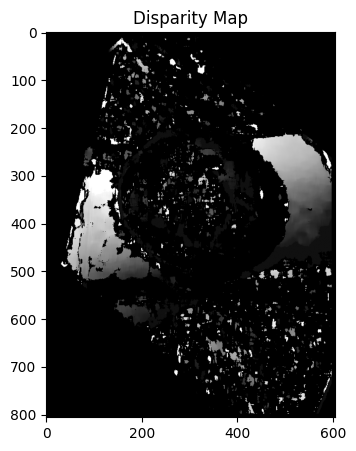

In [236]:
stereo = cv2.StereoBM_create(numDisparities=16, blockSize=15)
disparity = stereo.compute(img1_rect, img2_rect)

# Normalize the disparity map for visualization
disparity_normalized = cv2.normalize(disparity, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# Display the disparity map
plt.figure(figsize=(10, 5))
plt.imshow(disparity_normalized, 'gray')
plt.title('Disparity Map')
plt.show()

## Point Cloud Generation

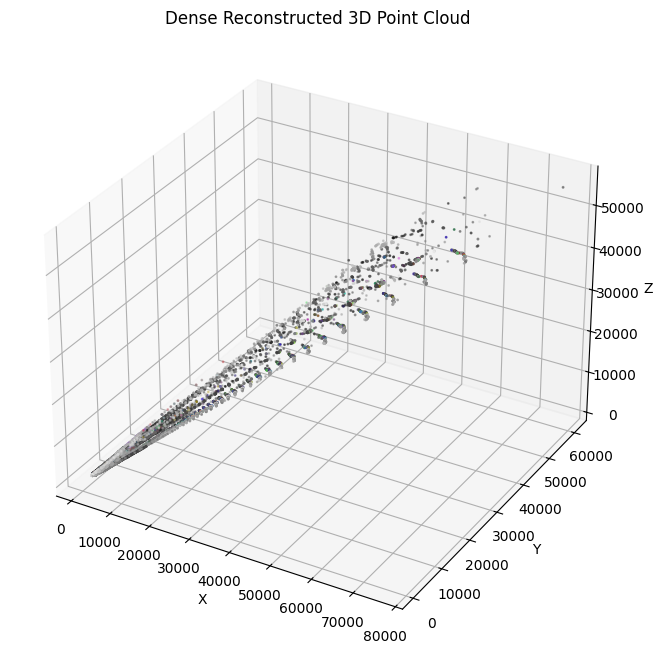

In [ ]:
points_3d = cv2.reprojectImageTo3D(disparity, Q)

# Filter out bad points (disparity == -1)
mask = disparity > disparity.min()
out_points = points_3d[mask]

# Get the colors for the points from the original image
colors = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
out_colors = colors[mask]

# This step is for visualization and debugging.
from mpl_toolkits.mplot3d import Axes3D

# Downsample the points for faster plotting
downsample_factor = 2
out_points_downsampled = out_points[::downsample_factor]
out_colors_downsampled = out_colors[::downsample_factor]

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(out_points_downsampled[:,0], out_points_downsampled[:,1], out_points_downsampled[:,2],
           c=out_colors_downsampled / 255.0, s=1)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Dense Reconstructed 3D Point Cloud')
plt.show()